# Decision curve analysis for the deployed 5-year model

Discrimination (C-index) says the model ranks patients correctly. Calibration
(`calibration.ipynb`) says its predicted risks are honest. Neither answers the
question a clinician actually has: **at the risk level where I'd escalate
surveillance for a patient, does using this model's risk score to decide who to
flag do any better than flagging everyone, or flagging no one?**

That is what decision curve analysis (DCA) answers. It is not a discrimination or
calibration metric - a model can have both and still be useless for decision-making
if its errors happen to fall in the range of thresholds anyone would actually use.
This notebook is a first pass: build the curve, validate it out-of-bag the same way
every other number in this repo is validated, and see whether it is worth keeping
in the thesis.

## The idea (Vickers & Elkin, 2006)

Pick a threshold probability $p_t$: the risk level at which you'd decide to act
(here, escalate surveillance). Flagging a patient is a bet - right if they recur,
wrong if they don't - and $p_t$ fixes the exchange rate between the two kinds of
being wrong, because a decision-maker who acts at $p_t$ is implicitly saying that
missing one recurrence is exactly as bad as $\frac{p_t}{1-p_t}$ unnecessary flags.
**Net benefit** turns that into a single number, in units of "true positives per
patient":

$$\text{NB}(p_t) = \frac{TP}{n} - \frac{FP}{n} \cdot \frac{p_t}{1-p_t}$$

Two fixed reference curves bound the question:

- **Flag none** - net benefit is 0 at every $p_t$, by definition.
- **Flag all** - net benefit is $\text{prevalence} - (1-\text{prevalence})\cdot
  \frac{p_t}{1-p_t}$, i.e. what you get from acting on no information at all.

A model earns its place only where its curve sits above *both* references. Below
that it is worse than doing nothing; above "flag all" but under "flag none" it is
worse than the null strategy of just flagging everybody.

## The survival extension, and why it matters here

Standard DCA assumes you know, for every patient, whether they had the event by
the horizon. With 27 events and heavy censoring that is false for almost this whole
cohort - most patients are censored well before 5 years, so "did they recur by
5y?" is unobserved for them. Vickers' survival extension (2008) resolves this the
same way `calibration.ipynb`'s per-zone table already does: within the flagged
group, $TP/n$ and $FP/n$ are not read off as raw proportions but estimated from
that subgroup's own Kaplan-Meier curve at the horizon,
$\widehat{TP/n} = \frac{n_{\text{flag}}}{n}\hat S_{\text{flag}}^c(t)$ where
$\hat S_{\text{flag}}^c(t) = 1 - \hat S_{\text{flag}}(t)$ is the KM cumulative
incidence inside the flagged subgroup. This notebook reuses the exact `km_table` /
`km_risk` primitives from `calibration.ipynb`, so the survival handling is
identical to everywhere else in the thesis - not a new assumption invented for
this notebook.

## Caveats to read the figures with

1. **27 events, total.** Net benefit inside a threshold's flagged subgroup is a
   Kaplan-Meier estimate on however many of those 27 fall in that subgroup - for
   the deployed high-risk zone (~15% of the cohort) that is on the order of 15-20
   events, not 27. The bootstrap bands below are the honest picture; the apparent
   curve alone would be optimistic, exactly as in `calibration.ipynb`.
2. **The event is rare.** Five-year regional LN recurrence risk is about 1.3%
   cohort-wide and about 6% in the deployed high-risk zone (`zone_summary.csv`).
   Net benefit values are correspondingly tiny, so they are reported per 1000
   patients, the usual convention for rare-outcome DCA.
3. **Competing events are treated as censoring**, exactly as in the Cox model
   itself - not a new limitation introduced here.
4. **This is a surveillance-intensity decision, not a treat/don't-treat one.**
   There is no fixed-cost intervention being withheld; "flag" means "escalate
   follow-up" and $p_t$ is the recurrence-risk level at which that seems worth it.
   The mathematics is unaffected, but read "net benefit" as "value of the
   escalation decision," not "value of a treatment."


In [1]:
# =============================================================================
# CONFIG - the single source of truth for this notebook.
# =============================================================================
CONFIG = {
    # ---- provenance ---------------------------------------------------------
    "repo_root": "../../../",
    "data_csv": "../../data/data_cox/data.csv",
    "diagnosis_txt": "../../data/data_cox/diagnosis.txt",
    "treatment_txt": "../../data/data_cox/treatment.txt",
    "bundle_metadata": "deployed_model/bundle_metadata.json",
    "thresholds_report_csv": "deployed_model/thresholds_report.csv",
    "output_dir": "decision_curve",

    # ---- cohort (identical to calibration.ipynb / threshold_2.0_copy.ipynb) -
    "event_col": "Regional LN recurrence",
    "time_col": "Survival days",
    "administrative_cap_days": 1826.0,
    "continuous_features": [
        "Age", "Ki67 positive cells (%) at CB", "Conventional RT fraction",
        "Total administered dose", "Boost dose administered",
    ],

    # ---- the fixed model - never re-tuned here, refitted inside every replicate
    "model_params": {"alphas": [0.000853168], "l1_ratio": 1.0, "fit_baseline_model": True},
    "expected_apparent_c_index": 0.9200067108464055,   # bundle_metadata.json

    # ---- internal validation: the repo's event-stratified bootstrap ---------
    # Same scheme as calibration.ipynb / threshold_2.0_copy.ipynb: one fit per
    # replicate, scored out-of-bag. Net benefit is reported out-of-bag, not
    # apparent, for the same reason every other metric in this repo is.
    "n_bootstrap": 300,
    "bootstrap_seed": 202609,
    "stratify_on_event": True,      # keeps all 27 events in every replicate
    "min_oob_events": 3,
    "progress_every": 25,
    "ci_alpha": 0.05,

    # ---- horizons -------------------------------------------------------------
    "horizons": [365.0, 1095.0, 1825.0],
    "primary_horizon": 1825.0,
    "time_display_divisor": 365.25,

    # ---- the decision curve itself --------------------------------------------
    "pt_max": 0.15,          # threshold probabilities swept from 0 to this
    "pt_points": 61,         # linspace resolution before the operating points are folded in
    "min_flagged": 1,        # fewer patients flagged than this -> net benefit defined as 0
    "nb_scale": 1000,        # net benefit is reported per this many patients

    # ---- presentation (matches calibration.ipynb / threshold_validation/) ---
    "figure_width_in": 7.0,
    "font_size": 9,
    "palette": {
        "model": "#0072B2", "flag_all": "#D55E00", "flag_none": "#333333",
        "operating_point": "#009E73",
    },
    "save_figures": True,
    "save_tables": True,
    "n_jobs": -1,
    "random_seed": 42,
}


In [2]:
# ---- Imports, export defaults and library versions --------------------------
import os
import sys
import json
import time
import platform
import warnings
from datetime import datetime

REPO_ROOT = os.path.abspath(CONFIG["repo_root"])
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import scipy.stats
import sklearn
import sksurv
import joblib
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import MinMaxScaler
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.metrics import concordance_index_censored

OUTPUT_DIR = os.path.abspath(CONFIG["output_dir"])
os.makedirs(OUTPUT_DIR, exist_ok=True)

# scikit-survival warns when the L1 path stops early on a resample - the premise of
# the bootstrap rather than news; a path that actually diverged is caught explicitly
# in run_replicate and counted as a failed replicate, not silenced. Workers are
# separate processes and do not inherit this filter, so run_replicate sets it again.
QUIET_WARNINGS = (ConvergenceWarning,)
for _cat in QUIET_WARNINGS:
    warnings.filterwarnings("ignore", category=_cat)

LIB_VERSIONS = {
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "scikit-survival": sksurv.__version__,
    "joblib": joblib.__version__, "matplotlib": matplotlib.__version__,
}
print("run started :", datetime.now().isoformat(timespec="seconds"))
print("output dir  :", OUTPUT_DIR)
print("library versions:")
for _k, _v in LIB_VERSIONS.items():
    print(f"  {_k:<16s} {_v}")

# Thesis export defaults: vector PDF, no in-figure titles, >= 8 pt type.
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.size": CONFIG["font_size"], "axes.titlesize": CONFIG["font_size"],
    "axes.labelsize": CONFIG["font_size"],
    "xtick.labelsize": CONFIG["font_size"] - 1, "ytick.labelsize": CONFIG["font_size"] - 1,
    "legend.fontsize": CONFIG["font_size"] - 1,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
})

DIV = float(CONFIG["time_display_divisor"])
PLO, PHI = 100 * CONFIG["ci_alpha"] / 2.0, 100 * (1.0 - CONFIG["ci_alpha"] / 2.0)

WRITTEN = []


def _save(fig, stem):
    """Write a figure as PNG + PDF into OUTPUT_DIR and record the paths."""
    if not CONFIG["save_figures"]:
        return
    for ext in ("png", "pdf"):
        path = os.path.join(OUTPUT_DIR, f"{stem}.{ext}")
        fig.savefig(path)
        WRITTEN.append(os.path.relpath(path, os.getcwd()))


def _save_table(df, stem, tex_caption=None, tex_label=None, float_format="%.4f"):
    """Write a table as CSV (always) and LaTeX (when a caption is supplied)."""
    if not CONFIG["save_tables"]:
        return
    path = os.path.join(OUTPUT_DIR, f"{stem}.csv")
    df.to_csv(path, index=False)
    WRITTEN.append(os.path.relpath(path, os.getcwd()))
    if tex_caption is not None:
        tex = df.to_latex(index=False, escape=True, float_format=float_format,
                          caption=tex_caption, label=tex_label, position="htbp")
        path = os.path.join(OUTPUT_DIR, f"{stem}.tex")
        with open(path, "w", encoding="utf-8") as fh:
            fh.write(tex)
        WRITTEN.append(os.path.relpath(path, os.getcwd()))


run started : 2026-09-01T11:35:58
output dir  : C:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\decision_curve
library versions:
  python           3.11.13
  numpy            2.3.1
  pandas           2.3.2
  scipy            1.16.2
  scikit-learn     1.7.2
  scikit-survival  0.25.0
  joblib           1.5.2
  matplotlib       3.10.6


## 1. Cohort and the fixed model

Same design matrix as every other notebook in `5y/`: same file, same administrative
cap, same feature columns, same L1-Coxnet at its deployed hyperparameters. Nothing
is re-tuned here. Because a decision curve only needs risk at the three reporting
horizons (not a fine time grid), predictions below are read at exactly those three
days rather than the ~120-point grid `calibration.ipynb` needs for its smooth
curves.

In [3]:
# ---- data_x (unscaled), y, and the three reporting horizons ------------------
_raw = pd.read_csv(CONFIG["data_csv"])
survival_dataset = _raw.drop(columns=[c for c in ["Unnamed: 0"] if c in _raw.columns])

with open(CONFIG["diagnosis_txt"], "r") as _f:
    diagnosis_variables = [line.strip() for line in _f if line.strip()]
with open(CONFIG["treatment_txt"], "r") as _f:
    treatment_variables = [line.strip() for line in _f if line.strip()]
feature_columns = treatment_variables + diagnosis_variables

_missing = [c for c in feature_columns if c not in survival_dataset.columns]
if _missing:
    raise KeyError(f"Feature columns absent from the data file: {_missing}")

# Administrative censoring at the cap (identical to the existing notebooks).
_cap = float(CONFIG["administrative_cap_days"])
_beyond = survival_dataset[CONFIG["time_col"]] > _cap
survival_dataset.loc[_beyond, CONFIG["event_col"]] = 0
survival_dataset.loc[_beyond, CONFIG["time_col"]] = _cap

data_x = survival_dataset[feature_columns].reset_index(drop=True)
y = Surv.from_arrays(
    event=survival_dataset[CONFIG["event_col"]],
    time=survival_dataset[CONFIG["time_col"]],
)
EVENT = y[y.dtype.names[0]].astype(bool)
TIME = y[y.dtype.names[1]].astype(float)
N_PATIENTS = int(data_x.shape[0])
COLS_TO_SCALE = [c for c in CONFIG["continuous_features"] if c in data_x.columns]

HORIZONS = np.asarray(sorted(CONFIG["horizons"]), dtype=float)
PRIMARY = float(CONFIG["primary_horizon"])
EVAL_TIMES = HORIZONS.copy()             # risk is only ever needed at these three days
HZ_IDX = np.arange(HORIZONS.size)

print(f"rows (patients)   : {N_PATIENTS}")
print(f"events by {_cap:.0f} d  : {int(EVENT.sum())}  ({100 * EVENT.mean():.2f}% of the cohort)")
print(f"censored          : {int((~EVENT).sum())}")
print(f"features          : {data_x.shape[1]}  (min-max scaled: {len(COLS_TO_SCALE)})")
print(f"horizons evaluated: " + ", ".join(f"{h / DIV:.0f}y" for h in HORIZONS))
print(f"events per horizon: "
      + ", ".join(f"{h / DIV:.0f}y={int((EVENT & (TIME <= h)).sum())}" for h in HORIZONS))


rows (patients)   : 3228
events by 1826 d  : 27  (0.84% of the cohort)
censored          : 3201
features          : 30  (min-max scaled: 5)
horizons evaluated: 1y, 3y, 5y
events per horizon: 1y=5, 3y=16, 5y=27


## 2. The apparent fit

Scaler and model fitted on all 3228 patients, then scored on the same 3228 - the
deployed model scoring the cohort it was built from. Reproducing the bundle's
C-index to 12 decimals is the check that this notebook is looking at the deployed
object and not a near-miss of it (identical assertion to `calibration.ipynb`).
Nothing here is validation; section 5 resamples the cohort and refits this same
configuration out-of-bag.

In [4]:
# ---- One fit: scale on train, fit Coxnet, return risk at EVAL_TIMES ----------
def fit_and_score(x_train, y_train, x_score, times):
    """Return (linear predictor, cumulative-incidence matrix, n non-zero coefs).

    `x_train` / `x_score` are UNSCALED frames; the min-max scaler is fitted on
    `x_train` only. The risk matrix is 1 - S(t) with S from the Breslow baseline
    that `fit_baseline_model=True` attaches to the fitted Coxnet. Identical to
    `calibration.ipynb`'s `fit_and_score`.
    """
    scaler = MinMaxScaler()
    xt, xs = x_train.copy(), x_score.copy()
    xt[COLS_TO_SCALE] = scaler.fit_transform(xt[COLS_TO_SCALE])
    xs[COLS_TO_SCALE] = scaler.transform(xs[COLS_TO_SCALE])

    model = CoxnetSurvivalAnalysis(**CONFIG["model_params"]).fit(xt, y_train)
    lp = np.asarray(model.predict(xs), dtype=float)

    fns = model.predict_survival_function(xs)
    t_max = float(max(f.x.max() for f in fns))
    t_eval = np.clip(np.asarray(times, dtype=float), None, t_max)
    risk = 1.0 - np.vstack([f(t_eval) for f in fns])
    n_nonzero = int((model.coef_[:, 0] != 0).sum())
    return lp, risk, n_nonzero, model, scaler


# ---- Apparent ---------------------------------------------------------------
_t0 = time.time()
LP_APPARENT, RISK_APPARENT, N_NONZERO, MODEL_FULL, SCALER_FULL = fit_and_score(
    data_x, y, data_x, EVAL_TIMES
)
C_APPARENT = float(concordance_index_censored(EVENT, TIME, LP_APPARENT)[0])

with open(CONFIG["bundle_metadata"], "r") as _f:
    BUNDLE_META = json.load(_f)
THRESH_REPORT = pd.read_csv(CONFIG["thresholds_report_csv"])

print(f"apparent fit          : {time.time() - _t0:.1f}s")
print(f"non-zero coefficients : {N_NONZERO} of {data_x.shape[1]}")
print(f"apparent C-index      : {C_APPARENT:.12f}")
print(f"bundle C-index        : {BUNDLE_META['c_index_train']:.12f}")
assert np.isclose(C_APPARENT, CONFIG["expected_apparent_c_index"], atol=1e-10), (
    "The refit does not reproduce the deployed model. Check data_cox/data.csv and "
    "CONFIG['model_params'] before reading anything below."
)
assert BUNDLE_META["n_patients"] == N_PATIENTS and BUNDLE_META["n_events"] == int(EVENT.sum())
print("-> matches the deployed bundle")

for _j, _h in enumerate(HORIZONS):
    _r = RISK_APPARENT[:, _j]
    print(f"  {_h / DIV:.0f}y apparent risk: mean {100 * _r.mean():.3f}%, "
          f"max {100 * _r.max():.3f}%, {np.unique(np.round(_r, 12)).size} distinct values")


apparent fit          : 0.3s
non-zero coefficients : 9 of 30
apparent C-index      : 0.920006710846
bundle C-index        : 0.920006710846
-> matches the deployed bundle
  1y apparent risk: mean 0.159%, max 5.860%, 213 distinct values
  3y apparent risk: mean 0.616%, max 21.139%, 213 distinct values
  5y apparent risk: mean 1.316%, max 40.313%, 213 distinct values


## 3. Net benefit - the primitives

`km_table` / `km_risk` below are byte-identical to `calibration.ipynb`'s (copied,
not re-derived), so the censoring handling here is exactly the machinery already
checked against brute force there.

`net_benefit_curve` flags $\{i : \text{risk}_i(t) \geq p_t\}$ at every $p_t$ on a
grid and reads $TP/n$, $FP/n$ off that subgroup's own Kaplan-Meier curve at $t$.
At $p_t = 0$ everyone is flagged, so the model curve must exactly equal the
"flag all" curve there - the sanity check run right after it.

In [5]:
# ---- Kaplan-Meier point estimate (identical to calibration.ipynb) -----------
def km_table(time, event):
    """(event times, deaths, at risk, S) on the distinct event times only."""
    t = np.asarray(time, dtype=float)
    e = np.asarray(event, dtype=bool)
    ut = np.unique(t[e])
    if ut.size == 0:
        return ut, ut.copy(), ut.copy(), ut.copy()
    order = np.argsort(t, kind="mergesort")
    ts = t[order]
    n_at_risk = len(ts) - np.searchsorted(ts, ut, side="left")
    deaths = np.array([np.count_nonzero((t == u) & e) for u in ut], dtype=float)
    S = np.cumprod(1.0 - deaths / n_at_risk)
    return ut, deaths, n_at_risk.astype(float), S


def km_risk(time, event, t):
    """Point estimate of 1 - S(t)."""
    ut, _, _, S = km_table(time, event)
    if ut.size == 0 or t < ut[0]:
        return 0.0
    return float(1.0 - S[np.searchsorted(ut, t, side="right") - 1])


# ---- Net benefit --------------------------------------------------------------
def net_benefit_curve(risk, time, event, t, pt_grid, min_flagged=1):
    """Net benefit of flagging {risk(t) >= pt} at every pt, at horizon t.

    Censoring inside the flagged group is resolved with that group's own
    Kaplan-Meier estimate (Vickers' 2008 survival extension), not a raw event
    proportion - the same logic as calibration.ipynb's per-zone table.
    """
    n = risk.size
    pt_grid = np.asarray(pt_grid, dtype=float)
    nb = np.zeros(pt_grid.size)
    n_flagged = np.zeros(pt_grid.size, dtype=int)
    events_flagged = np.zeros(pt_grid.size, dtype=int)
    for i, pt in enumerate(pt_grid):
        flagged = risk >= pt
        nf = int(flagged.sum())
        n_flagged[i] = nf
        if nf < min_flagged:
            continue                      # nobody flagged: net benefit is 0, by definition
        events_flagged[i] = int(event[flagged].sum())
        r_flag = km_risk(time[flagged], event[flagged], t)
        odds = pt / (1.0 - pt)
        nb[i] = (nf / n) * r_flag - (nf / n) * (1.0 - r_flag) * odds
    return nb, n_flagged, events_flagged


def net_benefit_flag_all(time, event, t, pt_grid):
    """Net benefit of flagging everyone: the fixed 'flag all' reference curve.
    'Flag none' is identically 0 at every pt and needs no function."""
    r_all = km_risk(time, event, t)
    pt_grid = np.asarray(pt_grid, dtype=float)
    odds = pt_grid / (1.0 - pt_grid)
    return r_all - (1.0 - r_all) * odds


print("primitives defined: km_table, km_risk, net_benefit_curve, net_benefit_flag_all")


primitives defined: km_table, km_risk, net_benefit_curve, net_benefit_flag_all


## 4. Apparent decision curves, and the deployed operating point

`THRESH_REPORT` (`deployed_model/thresholds_report.csv`) carries the deployed
model's own high-risk cutoff at each horizon - the $t_\text{high}(t)$ curve whose
crossing puts a patient in `zone_4_high`. Those three values are folded into the
threshold grid exactly, so the deployed rule is marked at the precise point on the
curve it actually sits at, not an interpolated neighbour.

In [6]:
# ---- The threshold-probability grid, exact deployed cutoffs included ---------
_lin = np.linspace(0.0, CONFIG["pt_max"], CONFIG["pt_points"])
_op_rows = THRESH_REPORT[THRESH_REPORT["time"].isin(HORIZONS)].sort_values("time")
assert len(_op_rows) == HORIZONS.size, "thresholds_report.csv does not cover all three horizons"
_op_pts = _op_rows["t_high"].to_numpy(float)

PT_GRID = np.unique(np.concatenate([_lin, _op_pts]))
PT_GRID = PT_GRID[PT_GRID <= CONFIG["pt_max"]]
OP_IDX = {float(h): int(np.flatnonzero(np.isclose(PT_GRID, pt))[0])
          for h, pt in zip(_op_rows["time"], _op_pts)}

print(f"threshold grid: {PT_GRID.size} points, 0-{100 * CONFIG['pt_max']:.0f}%")
print("deployed high-risk cutoff per horizon:")
for h in HORIZONS:
    print(f"  {h / DIV:.0f}y: t_high = {100 * PT_GRID[OP_IDX[h]]:.3f}%")

# ---- Apparent curves ----------------------------------------------------------
NB_MODEL_APPARENT, NB_ALL_APPARENT = {}, {}
for j, h in enumerate(HORIZONS):
    nb, n_flag, n_ev = net_benefit_curve(RISK_APPARENT[:, j], TIME, EVENT, h, PT_GRID,
                                         CONFIG["min_flagged"])
    NB_MODEL_APPARENT[h] = nb
    NB_ALL_APPARENT[h] = net_benefit_flag_all(TIME, EVENT, h, PT_GRID)
    assert np.isclose(nb[0], NB_ALL_APPARENT[h][0], atol=1e-12), (
        "at pt=0 the model curve must equal 'flag all': everyone is flagged either way")
    idx = OP_IDX[h]
    print(f"\n{h / DIV:.0f}y  at the deployed cutoff (pt={100 * PT_GRID[idx]:.3f}%): "
          f"{n_flag[idx]} flagged ({100 * n_flag[idx] / N_PATIENTS:.1f}% of the cohort), "
          f"{n_ev[idx]} raw events among them, "
          f"apparent net benefit = {CONFIG['nb_scale'] * nb[idx]:.2f} per {CONFIG['nb_scale']:,}")

print("\nsanity check passed: model curve meets 'flag all' at pt = 0, at every horizon")

# ---- Implied cost ratio behind the deployed cutoff (for context only) --------
_tp = BUNDLE_META["threshold_config"]["threshold_params"]
_fn_cost, _fp_cost = _tp["high_false_negative_cost"], _tp["high_false_positive_cost"]
IMPLIED_PT = _fp_cost / (_fp_cost + _fn_cost)
print(f"\nfor context: the ROC-utility rule that set the deployed cutoff used a "
      f"{_fn_cost:.0f}:{_fp_cost:.0f} missed-recurrence:unnecessary-flag cost ratio, "
      f"implying a threshold probability of {100 * IMPLIED_PT:.2f}% if costs were the only "
      f"input (deployed cutoffs above also reflect the empirical-Bayes shrinkage in "
      f"threshold_app.ipynb, so they do not match this number exactly).")


threshold grid: 64 points, 0-15%
deployed high-risk cutoff per horizon:
  1y: t_high = 0.283%
  3y: t_high = 1.108%
  5y: t_high = 2.392%

1y  at the deployed cutoff (pt=0.283%): 491 flagged (15.2% of the cohort), 21 raw events among them, apparent net benefit = 1.15 per 1,000

3y  at the deployed cutoff (pt=1.108%): 491 flagged (15.2% of the cohort), 21 raw events among them, apparent net benefit = 3.98 per 1,000

5y  at the deployed cutoff (pt=2.392%): 491 flagged (15.2% of the cohort), 21 raw events among them, apparent net benefit = 5.57 per 1,000

sanity check passed: model curve meets 'flag all' at pt = 0, at every horizon

for context: the ROC-utility rule that set the deployed cutoff used a 80:1 missed-recurrence:unnecessary-flag cost ratio, implying a threshold probability of 1.23% if costs were the only input (deployed cutoffs above also reflect the empirical-Bayes shrinkage in threshold_app.ipynb, so they do not match this number exactly).


## 5. Internal validation: the event-stratified bootstrap

Reading net benefit off the apparent fit is exactly the calibration mistake this
repo does not make anywhere else: the model is being asked how well it does on the
patients it was fitted to. Same fix as `calibration.ipynb` / `threshold_2.0_copy.ipynb`
- resample with replacement, stratified so every replicate keeps all 27 events,
refit, and score net benefit **out-of-bag only**. Curves are aggregated by taking
the median and a percentile band *across replicates*, not by pooling raw
predictions first, for the same reason `calibration.ipynb` avoids that: pooling
shrinks the spread and would flatter the result.

In [7]:
# ---- One bootstrap replicate: refit in-bag, net benefit out-of-bag -----------
def bootstrap_indices(rng, event, stratify_on_event):
    """In-bag row indices, size n, drawn with replacement. Stratifying on the
    event indicator keeps every replicate at the cohort's 27 events; an
    unstratified draw lands as low as 15 (same rule as threshold_2.0_copy.ipynb)."""
    n = int(event.size)
    if not stratify_on_event:
        return rng.choice(n, size=n, replace=True)
    event_rows = np.flatnonzero(event)
    censored_rows = np.flatnonzero(~event)
    return np.concatenate([
        rng.choice(event_rows, size=event_rows.size, replace=True),
        rng.choice(censored_rows, size=censored_rows.size, replace=True),
    ])


def run_replicate(replicate_index, seed):
    """One replicate. Never raises: a degenerate fit comes back with ok=False and
    its reason, so the failure rate is reported rather than silently absorbed."""
    started = time.perf_counter()
    for cat in QUIET_WARNINGS:
        warnings.filterwarnings("ignore", category=cat)
    try:
        rng = np.random.default_rng(seed)
        inbag = bootstrap_indices(rng, EVENT, CONFIG["stratify_on_event"])
        oob = np.setdiff1d(np.arange(N_PATIENTS), np.unique(inbag), assume_unique=True)
        n_oob_events = int(EVENT[oob].sum())
        if n_oob_events < CONFIG["min_oob_events"]:
            raise ValueError(f"{n_oob_events} out-of-bag events, below "
                             f"CONFIG['min_oob_events'] = {CONFIG['min_oob_events']}")

        # The L1 path diverges on a small minority of resamples (coefficients
        # blow up, the Breslow baseline comes back NaN); overflow is silenced here
        # because the divergence is caught explicitly below and counted as a
        # failed replicate, exactly as in calibration.ipynb.
        with np.errstate(over="ignore", invalid="ignore"):
            lp_oob, risk_oob, n_nonzero, _, _ = fit_and_score(
                data_x.iloc[inbag], y[inbag], data_x.iloc[oob], EVAL_TIMES)

        n_bad_rows = int(np.count_nonzero(~np.isfinite(risk_oob).all(axis=1)))
        if not np.all(np.isfinite(lp_oob)) or n_bad_rows:
            raise ValueError(
                f"the L1 path diverged: {int((~np.isfinite(lp_oob)).sum())} non-finite "
                f"linear predictors, {n_bad_rows} rows with a non-finite survival curve")
        if float(np.ptp(risk_oob[:, -1])) <= 0.0:
            raise ValueError("degenerate risk matrix (the L1 path diverged)")

        t_oob, e_oob = TIME[oob], EVENT[oob]
        nb_model, nb_all = {}, {}
        for j, h in enumerate(HORIZONS):
            nb, _, _ = net_benefit_curve(risk_oob[:, j], t_oob, e_oob, h, PT_GRID,
                                         CONFIG["min_flagged"])
            nb_model[h] = nb.astype(np.float32)
            nb_all[h] = net_benefit_flag_all(t_oob, e_oob, h, PT_GRID).astype(np.float32)

        return {
            "ok": True, "replicate": replicate_index, "seed": seed,
            "n_oob": int(oob.size), "n_oob_events": n_oob_events,
            "n_nonzero_coef": int(n_nonzero),
            "nb_model": nb_model, "nb_all": nb_all,
            "seconds": time.perf_counter() - started,
        }
    except Exception as exc:
        return {"ok": False, "replicate": replicate_index, "seed": seed,
                "error": f"{type(exc).__name__}: {exc}",
                "seconds": time.perf_counter() - started}


In [8]:
# ---- Run the bootstrap ------------------------------------------------------
B = int(CONFIG["n_bootstrap"])
SEEDS = [int(s.generate_state(1)[0]) for s in
         np.random.SeedSequence(CONFIG["bootstrap_seed"]).spawn(B)]

_nb_model_runs = {float(h): [] for h in HORIZONS}
_nb_all_runs = {float(h): [] for h in HORIZONS}
_log, _failed = [], []

print(f"running {B} replicates on n_jobs={CONFIG['n_jobs']} (master seed {CONFIG['bootstrap_seed']})")
_t0 = time.perf_counter()
_done = 0
_parallel = Parallel(n_jobs=CONFIG["n_jobs"], return_as="generator_unordered")
for _p in _parallel(delayed(run_replicate)(_b, SEEDS[_b]) for _b in range(B)):
    _done += 1
    if _p["ok"]:
        for h in HORIZONS:
            _nb_model_runs[float(h)].append(_p["nb_model"][float(h)])
            _nb_all_runs[float(h)].append(_p["nb_all"][float(h)])
        _log.append({k: _p[k] for k in ("replicate", "seed", "n_oob", "n_oob_events",
                                        "n_nonzero_coef", "seconds")})
    else:
        _failed.append(_p)
    if _done % CONFIG["progress_every"] == 0 or _done == B:
        _el = time.perf_counter() - _t0
        print(f"  {_done:>4d}/{B}   elapsed {_el / 60:.1f} min   "
              f"ETA {_el / _done * (B - _done) / 60:.1f} min", flush=True)

N_OK = len(_log)
if N_OK == 0:
    raise RuntimeError("every replicate failed - nothing to aggregate")

REPLICATE_LOG = pd.DataFrame(_log).sort_values("replicate").reset_index(drop=True)
FAILURES = (pd.DataFrame([{k: f[k] for k in ("replicate", "seed", "error")} for f in _failed])
            if _failed else pd.DataFrame(columns=["replicate", "seed", "error"]))

print(f"\nfinished in {(time.perf_counter() - _t0) / 60:.1f} min")
print(f"successful replicates : {N_OK}/{B}")
print(f"degenerate replicates : {len(_failed)}/{B} ({100.0 * len(_failed) / B:.1f}%)")
if _failed:
    for _msg, _cnt in pd.Series([f["error"] for f in _failed]).value_counts().items():
        print(f"    {_cnt:>4d}x  {_msg}")
    if len(_failed) / B > 0.10:
        print(f"  WARNING: {100.0 * len(_failed) / B:.0f}% of replicates failed - the "
              f"surviving {N_OK} are the subset on which this fit happens to converge "
              f"and are NOT a random sample of resamples.")

_ns = REPLICATE_LOG["n_oob"].to_numpy(float)
_ne = REPLICATE_LOG["n_oob_events"].to_numpy(float)
print(f"\nout-of-bag rows   : mean {_ns.mean():.0f} ({_ns.min():.0f}-{_ns.max():.0f}), "
      f"{100 * _ns.mean() / N_PATIENTS:.1f}% of the cohort")
print(f"out-of-bag events : mean {_ne.mean():.1f} ({_ne.min():.0f}-{_ne.max():.0f}) of "
      f"{int(EVENT.sum())}")

# ---- Aggregate: median + percentile band, computed inside each replicate first --
NB_MODEL_OOB, NB_ALL_OOB = {}, {}
for h in HORIZONS:
    h = float(h)
    m = np.vstack(_nb_model_runs[h])
    a = np.vstack(_nb_all_runs[h])
    NB_MODEL_OOB[h] = {"median": np.median(m, axis=0),
                        "lo": np.percentile(m, PLO, axis=0),
                        "hi": np.percentile(m, PHI, axis=0)}
    NB_ALL_OOB[h] = {"median": np.median(a, axis=0),
                      "lo": np.percentile(a, PLO, axis=0),
                      "hi": np.percentile(a, PHI, axis=0)}
print("\nout-of-bag net benefit curves aggregated at", ", ".join(f"{h/DIV:.0f}y" for h in HORIZONS))


running 300 replicates on n_jobs=-1 (master seed 202609)


    25/300   elapsed 0.2 min   ETA 2.0 min


    50/300   elapsed 0.2 min   ETA 1.0 min


    75/300   elapsed 0.2 min   ETA 0.7 min


   100/300   elapsed 0.3 min   ETA 0.5 min


   125/300   elapsed 0.3 min   ETA 0.4 min


... (4 outputs left out)

   250/300   elapsed 0.4 min   ETA 0.1 min


   275/300   elapsed 0.4 min   ETA 0.0 min


   300/300   elapsed 0.5 min   ETA 0.0 min



finished in 0.5 min
successful replicates : 299/300
degenerate replicates : 1/300 (0.3%)
       1x  ArithmeticError: Numerical error, because weights are too large. Consider increasing alpha.

out-of-bag rows   : mean 1187 (1138-1236), 36.8% of the cohort
out-of-bag events : mean 9.7 (6-14) of 27

out-of-bag net benefit curves aggregated at 1y, 3y, 5y


## 6. Figures

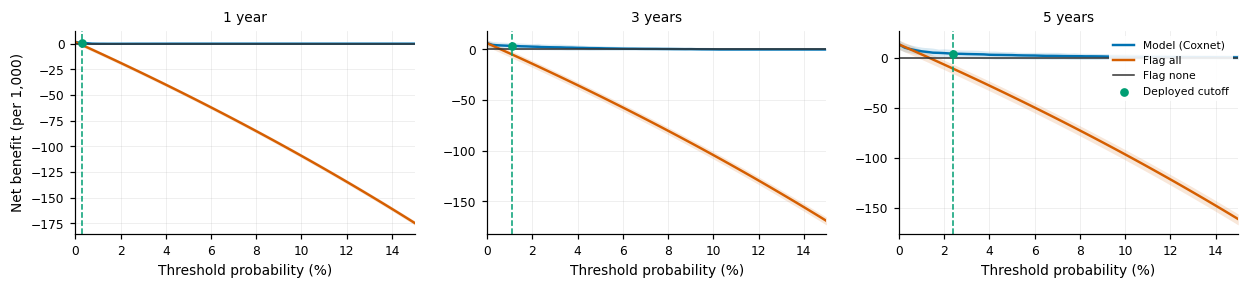

In [9]:
# ---- Figure A: out-of-bag decision curves at all three horizons --------------
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(CONFIG["figure_width_in"] * 1.65, 2.7),
                         sharey=False)
scale = CONFIG["nb_scale"]
pal = CONFIG["palette"]
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    h = float(h)
    x = 100 * PT_GRID
    ax.plot(x, scale * NB_MODEL_OOB[h]["median"], color=pal["model"], label="Model (Coxnet)")
    ax.fill_between(x, scale * NB_MODEL_OOB[h]["lo"], scale * NB_MODEL_OOB[h]["hi"],
                    color=pal["model"], alpha=0.15, linewidth=0)
    ax.plot(x, scale * NB_ALL_OOB[h]["median"], color=pal["flag_all"], label="Flag all")
    ax.fill_between(x, scale * NB_ALL_OOB[h]["lo"], scale * NB_ALL_OOB[h]["hi"],
                    color=pal["flag_all"], alpha=0.15, linewidth=0)
    ax.axhline(0.0, color=pal["flag_none"], linewidth=1.0, label="Flag none")
    idx = OP_IDX[h]
    ax.axvline(100 * PT_GRID[idx], color=pal["operating_point"], linestyle="--", linewidth=1.0)
    ax.scatter([100 * PT_GRID[idx]], [scale * NB_MODEL_OOB[h]["median"][idx]],
              color=pal["operating_point"], zorder=5, s=22, label="Deployed cutoff")
    ax.set_title(f"{h / DIV:.0f} year" + ("" if h == 365 else "s"))
    ax.set_xlabel("Threshold probability (%)")
    ax.set_xlim(0, 100 * CONFIG["pt_max"])
axes[0].set_ylabel(f"Net benefit (per {scale:,})")
axes[-1].legend(loc="upper right", frameon=True, framealpha=0.9, edgecolor="none", fontsize=CONFIG["font_size"] - 2)
fig.tight_layout()
_save(fig, "figA_decision_curve_oob")
plt.show()


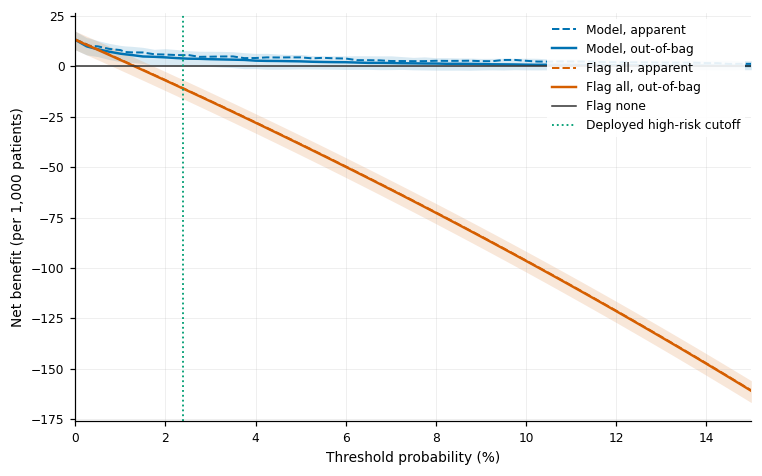

In [10]:
# ---- Figure B: the thesis figure - apparent vs out-of-bag at 5 years ---------
fig, ax = plt.subplots(figsize=(CONFIG["figure_width_in"], 4.4))
h = PRIMARY
x = 100 * PT_GRID
ax.plot(x, scale * NB_MODEL_APPARENT[h], color=pal["model"], linestyle="--", linewidth=1.3,
       label="Model, apparent")
ax.plot(x, scale * NB_MODEL_OOB[h]["median"], color=pal["model"], label="Model, out-of-bag")
ax.fill_between(x, scale * NB_MODEL_OOB[h]["lo"], scale * NB_MODEL_OOB[h]["hi"],
               color=pal["model"], alpha=0.15, linewidth=0)
ax.plot(x, scale * NB_ALL_APPARENT[h], color=pal["flag_all"], linestyle="--", linewidth=1.3,
       label="Flag all, apparent")
ax.plot(x, scale * NB_ALL_OOB[h]["median"], color=pal["flag_all"], label="Flag all, out-of-bag")
ax.fill_between(x, scale * NB_ALL_OOB[h]["lo"], scale * NB_ALL_OOB[h]["hi"],
               color=pal["flag_all"], alpha=0.15, linewidth=0)
ax.axhline(0.0, color=pal["flag_none"], linewidth=1.0, label="Flag none")
idx = OP_IDX[h]
ax.axvline(100 * PT_GRID[idx], color=pal["operating_point"], linestyle=":", linewidth=1.2,
          label="Deployed high-risk cutoff")
ax.set_xlabel("Threshold probability (%)")
ax.set_ylabel(f"Net benefit (per {scale:,} patients)")
ax.set_xlim(0, 100 * CONFIG["pt_max"])
ax.legend(loc="upper right", frameon=True, framealpha=0.9, edgecolor="none", fontsize=CONFIG["font_size"] - 1)
fig.tight_layout()
_save(fig, "figB_apparent_vs_oob_5y")
plt.show()


## 7. Table

In [11]:
# ---- Table 1: net benefit at round thresholds and the deployed cutoff, 5y ----
h = PRIMARY
_round_pts = np.array([0.005, 0.01, 0.02, 0.05, 0.10])
_op_pt = PT_GRID[OP_IDX[h]]
_targets = np.unique(np.concatenate([_round_pts, [_op_pt]]))

_rows = []
for pt in _targets:
    idx = int(np.argmin(np.abs(PT_GRID - pt)))
    is_op = bool(np.isclose(PT_GRID[idx], _op_pt))
    nb_m_a = NB_MODEL_APPARENT[h][idx]
    nb_m_o = NB_MODEL_OOB[h]["median"][idx]
    nb_a_o = NB_ALL_OOB[h]["median"][idx]
    interventions_avoided = ((nb_m_o - nb_a_o) * (1.0 - PT_GRID[idx])
                             / max(PT_GRID[idx], 1e-9) * scale)
    _rows.append({
        "pt_pct": round(100 * PT_GRID[idx], 3),
        "label": "deployed high-risk cutoff" if is_op else "",
        "nb_model_apparent": scale * nb_m_a,
        "nb_model_oob_median": scale * nb_m_o,
        "nb_model_oob_lo": scale * NB_MODEL_OOB[h]["lo"][idx],
        "nb_model_oob_hi": scale * NB_MODEL_OOB[h]["hi"][idx],
        "nb_flag_all_oob_median": scale * nb_a_o,
        "interventions_avoided_per_1000_vs_flag_all_oob": interventions_avoided,
    })

TABLE1 = pd.DataFrame(_rows).drop_duplicates(subset="pt_pct").sort_values("pt_pct").reset_index(drop=True)
_save_table(TABLE1, "table1_net_benefit_5y",
           tex_caption="Net benefit at 5 years, apparent and out-of-bag, per 1000 patients.",
           tex_label="tab:dca-net-benefit-5y", float_format="%.2f")
pd.set_option("display.width", 200)
print(TABLE1.to_string(index=False))
print(f"""
'interventions avoided vs flag all' is (NB_model - NB_flag_all) x (1-pt)/pt x 1000: how
many fewer patients per 1000 would need to be flagged to match 'flag all's net benefit,
if flagging were driven by the model instead. Positive means the model is doing some of
the same job with fewer flags; negative means 'flag all' is doing better at that
threshold and the model curve is not worth using there.
""")


 pt_pct                     label  nb_model_apparent  nb_model_oob_median  nb_model_oob_lo  nb_model_oob_hi  nb_flag_all_oob_median  interventions_avoided_per_1000_vs_flag_all_oob
  0.500                                     9.948421             8.510410         4.858326        12.778096                8.204027                                       60.970358
  1.000                                     8.085428             6.297344         2.352157        10.417792                3.194957                                      307.136320
  2.000                                     5.865783             4.474499         0.231929         8.784450               -6.976523                                      561.100112
  2.392 deployed high-risk cutoff           5.565398             3.946126        -0.008607         7.934750              -11.017492                                      610.684299
  5.000                                     4.465864             2.495178        -1.272117         5

## 8. Reproducibility

In [12]:
# ---- Run metadata -------------------------------------------------------------
RUN_METADATA = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "notebook": "decision_curve.ipynb",
    "model_source": CONFIG["bundle_metadata"],
    "library_versions": LIB_VERSIONS,
    "config": CONFIG,
    "apparent": {"c_index": C_APPARENT, "n_nonzero_coef": N_NONZERO},
    "bootstrap": {
        "n_requested": B, "n_ok": N_OK, "n_failed": len(_failed),
        "failure_rate": len(_failed) / B,
        "mean_seconds_per_replicate": float(REPLICATE_LOG["seconds"].mean()),
    },
    "deployed_operating_point_5y": {
        "pt_pct": float(100 * PT_GRID[OP_IDX[PRIMARY]]),
        "nb_model_apparent_per_1000": float(scale * NB_MODEL_APPARENT[PRIMARY][OP_IDX[PRIMARY]]),
        "nb_model_oob_median_per_1000": float(scale * NB_MODEL_OOB[PRIMARY]["median"][OP_IDX[PRIMARY]]),
        "nb_flag_all_oob_median_per_1000": float(scale * NB_ALL_OOB[PRIMARY]["median"][OP_IDX[PRIMARY]]),
    },
    "files_written": WRITTEN,
}
with open(os.path.join(OUTPUT_DIR, "run_metadata.json"), "w", encoding="utf-8") as fh:
    json.dump(RUN_METADATA, fh, indent=2, default=str)
WRITTEN.append(os.path.relpath(os.path.join(OUTPUT_DIR, "run_metadata.json"), os.getcwd()))

print("files written:")
for _w in WRITTEN:
    print(" ", _w)


files written:
  decision_curve\figA_decision_curve_oob.png
  decision_curve\figA_decision_curve_oob.pdf
  decision_curve\figB_apparent_vs_oob_5y.png
  decision_curve\figB_apparent_vs_oob_5y.pdf
  decision_curve\table1_net_benefit_5y.csv
  decision_curve\table1_net_benefit_5y.tex
  decision_curve\run_metadata.json


In [13]:
# ---- Does DCA earn its place in the thesis? -----------------------------------
h = PRIMARY
idx_op = OP_IDX[h]
gap_op = scale * (NB_MODEL_OOB[h]["median"][idx_op] - NB_ALL_OOB[h]["median"][idx_op])
above_all = NB_MODEL_OOB[h]["median"] > NB_ALL_OOB[h]["median"]
above_none = NB_MODEL_OOB[h]["median"] > 0.0
both = above_all & above_none
_frac_useful = float(both.mean())
if both.any():
    _lo_pt = 100 * PT_GRID[both][0]
    _hi_pt = 100 * PT_GRID[both][-1] if both[-1] or both.sum() > 1 else _lo_pt
else:
    _lo_pt = _hi_pt = float("nan")

print(f"At the deployed 5-year cutoff (pt={100 * PT_GRID[idx_op]:.2f}%), the out-of-bag "
      f"median model curve sits {gap_op:+.2f} net-benefit-per-1000 {'above' if gap_op > 0 else 'below'} "
      f"'flag all', with a band spanning "
      f"[{scale * NB_MODEL_OOB[h]['lo'][idx_op]:.2f}, {scale * NB_MODEL_OOB[h]['hi'][idx_op]:.2f}].")
print(f"\nOver the swept range (0-{100 * CONFIG['pt_max']:.0f}%), the median out-of-bag model "
      f"curve beats BOTH references on {100 * _frac_useful:.0f}% of threshold points"
      + (f", roughly {_lo_pt:.1f}-{_hi_pt:.1f}%." if both.any() else ", i.e. nowhere - it never "
         "clears both bounds at once on this grid."))
print("""
Read this alongside two things already established elsewhere in the thesis:

- the ridge behind the deployed cutoff (see threshold_validation_spec.md /
  threshold_2.0_copy.ipynb) is wide and not sharply identified, so a curve that looks
  flat across a broad pt range here is not a new finding, it is the same
  non-identifiability showing up in a different plot.
- Only 27 events total back every one of these curves. Wide out-of-bag bands are the
  honest consequence, not a sign the computation is wrong.

Whether this is worth a figure in the thesis body depends on what it is being used to
argue. If the goal is "the deployed rule is not obviously worse than the naive
alternatives it will be compared against," this is reasonably good evidence for that,
with the caveats above attached. If the goal is a tight, well-separated demonstration
that the model adds clinical value at a specific threshold, this rare-event, low-signal
cohort is a hard setting for DCA to deliver that crisply - the same story calibration.ipynb
tells about needing 4 risk groups instead of deciles. An annex figure with the caveats
stated seems like the more defensible use of this than a headline claim.
""")


At the deployed 5-year cutoff (pt=2.39%), the out-of-bag median model curve sits +14.96 net-benefit-per-1000 above 'flag all', with a band spanning [-0.01, 7.93].

Over the swept range (0-15%), the median out-of-bag model curve beats BOTH references on 95% of threshold points, roughly 0.5-15.0%.

Read this alongside two things already established elsewhere in the thesis:

- the ridge behind the deployed cutoff (see threshold_validation_spec.md /
  threshold_2.0_copy.ipynb) is wide and not sharply identified, so a curve that looks
  flat across a broad pt range here is not a new finding, it is the same
  non-identifiability showing up in a different plot.
- Only 27 events total back every one of these curves. Wide out-of-bag bands are the
  honest consequence, not a sign the computation is wrong.

Whether this is worth a figure in the thesis body depends on what it is being used to
argue. If the goal is "the deployed rule is not obviously worse than the naive
alternatives it will be com